# Assignment 1, Part 1 — EDA and the leakage-free preprocessing pipeline

**NHAMCS 2022 Emergency Department · target `IMMEDR` (5-class) · primary metric macro-F1**

Part 1 of CS-13410. This notebook does three things, in order:

1. Loads the **official** CDC/NCHS file and verifies it byte-for-byte.
2. Explores the target and the selected features (**4 figures**).
3. Builds the `Pipeline`/`ColumnTransformer` and **demonstrates** that every
   learned parameter comes from training data only.

**No classifier is trained and no accuracy figure is reported.** That is Part 2.

Supporting documents: `docs/assignment1_proposal.md`,
`docs/feature_register.md`, `docs/methodology.md`.

> **NOT CLINICAL DECISION SUPPORT.** Triage acuity reflects local protocol and
> clinician judgement. Nothing here may be used to triage a real patient.

## 0. Setup

The dataset path is **never hard-coded**. `src/config.py` resolves it from, in
order: an explicit argument, the `NHAMCS_DATASET_PATH` environment variable, then
a documented sibling location. The raw file is read-only, is excluded by
`.gitignore`, and is not committed to this repository.

In [1]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

import sys

REPO = Path.cwd().resolve()
if not (REPO / "src").is_dir():          # tolerate being run from notebooks/
    REPO = REPO.parent
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from src import config
from src.data import dataset, target
from src.preprocessing import features as ft
from src.preprocessing import sentinels as sn

FIG_DIR = REPO / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

print("repo       :", REPO)
print("python     :", sys.version.split()[0])
for lib in (pd, np, matplotlib):
    print(f"{lib.__name__:12s}", lib.__version__)
print("sklearn    :", __import__("sklearn").__version__)
print("RANDOM_STATE:", config.RANDOM_STATE)

repo       : C:\Projects\NHAMCS-TriageML
python     : 3.13.5
pandas       2.3.0
numpy        2.2.6
matplotlib   3.11.2
sklearn    : 1.7.0
RANDOM_STATE: 42


## 1. Load and verify the official dataset

The file is gated on **size *and* SHA-256**. A digest match establishes
byte-identity, so the loader refuses to proceed rather than analysing a wrong or
substituted file.

In [2]:
dataset_path = config.resolve_dataset_path()
print("resolved path:", dataset_path)

report = dataset.verify_dataset(dataset_path)
report_frame = pd.DataFrame(
    {"property": list(report), "value": [str(v) for v in report.values()]}
)
report_frame

resolved path: C:\Projects\ML_Dataset_Audit\NHAMCS_2022\raw\nhamcs_ed_2022\ed2022-stata.dta


,property,value
0,path,C:\Projects\ML_Dataset_Audit\NHAMCS_2022\raw\nhamcs_ed_2...
1,filename,ed2022-stata.dta
2,size_bytes,37720094
3,expected_size_bytes,37720094
4,sha256,0E00CD5AEA4511CD619F7AF1E0DC2F6825F111B7C87D3EBBB1358410...
5,expected_sha256,0E00CD5AEA4511CD619F7AF1E0DC2F6825F111B7C87D3EBBB1358410...
6,expected_shape,"(16025, 913)"
7,size_matches,True
8,sha256_matches,True
9,verified,True


In [3]:
print("size matches :", report["size_matches"])
print("sha256 match :", report["sha256_matches"])
print("VERIFIED     :", report["verified"])
assert report["verified"], "Dataset integrity check failed - refusing to continue"

size matches : True
sha256 match : True
VERIFIED     : True


`convert_categoricals=False` is mandatory, not stylistic. pandas' default
converter raises `ValueError` on this official file because the value-label set for
`TEMPF` contains a duplicate label. The flag keeps the original numeric codes, which
this project needs in order to apply the codebook's sentinel rules explicitly.

In [4]:
full = dataset.load_raw_dataset(dataset_path)
print("full file    :", full.shape, "(16,025 visits x 913 variables)")
print("columns      :", len(full.columns))
full.head(3)[["IMMEDR", "ARRTIME", "TEMPF", "PULSE", "BPSYS", "BPDIAS", "RFV13D"]]

full file    : (16025, 913) (16,025 visits x 913 variables)
columns      : 913


,IMMEDR,ARRTIME,TEMPF,PULSE,BPSYS,BPDIAS,RFV13D
0,3,0604,984,72,104,66,1545
1,-9,1053,983,67,105,67,1525
2,3,1419,987,79,144,82,1260


## 2. Target definition and the modelling population

`IMMEDR` is the nurse-recorded triage level. It is **five-class**, ordinal, and
severely imbalanced.

Two of the excluded codes are the ones that matter. `0` ("no triage recorded,
although this ESA does conduct triage") and `7` ("this ESA does not conduct
nursing triage") are *documentation states*, not urgency levels. Folding them into
the target would ask the model to predict whether a facility documented its
triage decision — a different question from clinical urgency.

In [5]:
target_summary = target.target_summary(full)
target_summary

,code,label,n,pct,pct_of_rows_supplied
0,1,Immediate,139,1.36,0.87
1,2,Emergent,1595,15.63,9.95
2,3,Urgent,5340,52.32,33.32
3,4,Semi-urgent,2826,27.69,17.63
4,5,Nonurgent,307,3.01,1.92


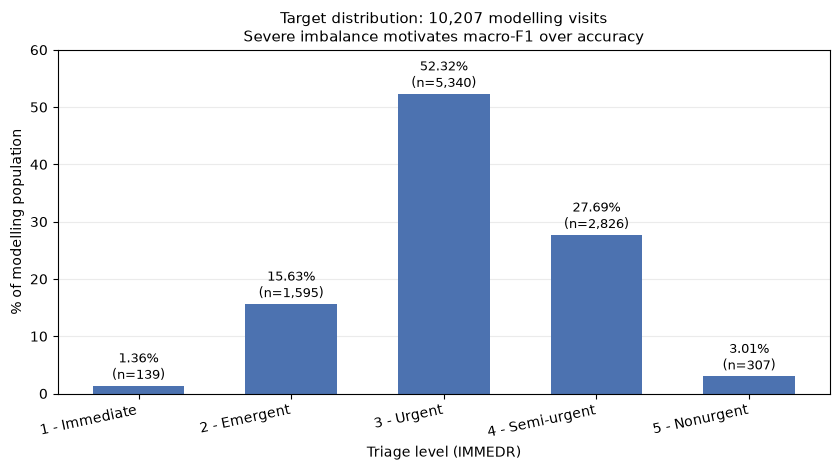

In [6]:
# The imbalance is the reason macro-F1 is the primary metric rather than accuracy.
figure, axis = plt.subplots(figsize=(8.5, 4.8))
positions = np.arange(len(target_summary))
bars = axis.bar(positions, target_summary["pct"], color="#4C72B0", width=0.6)
axis.set_xticks(positions)
axis.set_xticklabels(
    [f"{row.code} - {row.label}" for row in target_summary.itertuples()],
    rotation=12, ha="right",
)
axis.set_ylabel("% of modelling population")
axis.set_xlabel("Triage level (IMMEDR)")
axis.set_title("Target distribution: 10,207 modelling visits\nSevere imbalance motivates macro-F1 over accuracy", fontsize=11)
axis.set_ylim(0, 60)
axis.grid(axis="y", alpha=0.25)
axis.set_axisbelow(True)
for bar, row in zip(bars, target_summary.itertuples()):
    axis.text(
        bar.get_x() + bar.get_width() / 2, row.pct + 1.2,
        f"{row.pct:.2f}%\n(n={row.n:,})", ha="center", fontsize=9,
    )
figure.tight_layout()
figure.savefig(FIG_DIR / "fig01_target_distribution.png", dpi=150)
plt.show()

In [7]:
print("majority-class baseline (accuracy floor):", round(target.majority_class_baseline(full), 4))

majority-class baseline (accuracy floor): 0.5232


In [8]:
exclusions = target.exclusion_summary(full)
exclusions

,code,reason,n,pct_of_file
0,-9,Blank (non-response),364,2.27
1,-8,Unknown (non-response),3788,23.64
2,0,"No triage recorded for this visit, but the ESA does cond...",587,3.66
3,7,Visit occurred in an ESA that does not conduct nursing t...,1079,6.73


## 3. Feature selection — what was excluded and why

Selection followed the external forensic audit of all 913 variables. The
governing question for each variable is *when was it recorded relative to the
triage decision*.

The most consequential exclusion is the demographics. `AGE`, `SEX`, `RACER`,
`RACERETH`, `RACEUN`, `ETHIM`, `ETHUN` were imputed by NCHS using a model that
**took triage level as an input**. They are leakage, not merely "recorded later".

In [9]:
ft.eligibility_class_summary()

,class,meaning,n,part1_decision
0,A,Timing-eligible,13,INCLUDED
1,B (RFV),Conditional: reason for visit,10,"INCLUDED (4-digit forms only, assumption stated)"
2,B (other),"Conditional: payment, PAINSCALE, EPISODE",12,EXCLUDED (collection point unresolved)
3,C,Recorded after the triage decision,794,EXCLUDED
4,D,Derived from class C,5,EXCLUDED
5,E,Key / admin / survey design,13,EXCLUDED
6,F,Facility-only (constant within HOSPCODE),41,EXCLUDED
7,G,Timing unresolved,24,EXCLUDED
8,T,Target (IMMEDR),1,TARGET


In [10]:
# Leakage guards run at pipeline-construction time, and again here.
ft.leakage_checks(ft.FEATURES)

,check,detail,result
0,target absent from feature list,'IMMEDR' not in the 20 features,PASS
1,hospital / survey identifiers absent,"none of CPSUM, CSTRATM, HOSPCODE, PATCODE",PASS
2,target-imputed demographics absent,"none of AGE, ETHIM, ETHUN, RACER, RACERETH, RACEUN, SEX",PASS
3,no unrecognised columns,all 20 map to the documented register,PASS
4,register draws on 18 raw variables,18 declared raw source variables,PASS


## 4. Data quality — sentinel resolution

Sentinel codes are classified individually, because `-9`, `-8`, `-7` and `0` mean
three genuinely different things here: a recorded non-response, a structural
non-applicability, or a genuine absence.

The structural case is not academic. `AMBTRANSFER = -7` applies to 80.6% of the
modelling population, because the item only applies to ambulance arrivals. Treating
it as missing data would invent an 80% missingness rate and then impute away a
meaningful structural fact.

In [11]:
population = target.select_modelling_population(full)
print("modelling population:", population.shape[0], "visits")

X = sn.build_modelling_frame(population)
y = population[target.TARGET_COLUMN]        # the label, kept strictly separate from X
print("engineered frame   :", X.shape)
print()
print(f"{len(ft.FEATURES)} engineered columns, derived from "
      f"{len(ft.RAW_SOURCE_VARIABLES)} raw source variables")
print("(PULSE and BPDIAS each contribute a value column and a method-flag column)")
print()
print("Raw source variables in the register:")
print("  " + ", ".join(ft.RAW_SOURCE_VARIABLES))

modelling population: 10207 visits
engineered frame   : (10207, 20)

20 engineered columns, derived from 18 raw source variables
(PULSE and BPDIAS each contribute a value column and a method-flag column)

Raw source variables in the register:
  ARRTIME, TEMPF, PULSE, RESPR, BPSYS, BPDIAS, POPCT, VMONTH, VDAYR, RESIDNCE, ARREMS, AMBTRANSFER, SEEN72, RFV13D, RFV23D, RFV33D, RFV43D, RFV53D


### Cleaning is row-local

No value is computed from any other row, so the cleaning step cannot itself
transfer information. Verified by shuffling the rows and asserting equality.

In [12]:
shuffled = sn.build_modelling_frame(
    population.sample(frac=1.0, random_state=config.RANDOM_STATE).sort_index()
)
identical = X.astype(str).equals(shuffled.astype(str))
print("row order does not change the result:", identical)
assert identical

row order does not change the result: True


### The `998` trap

`998` is a **method code** in `PULSE` and `BPDIAS` — the value was obtained by
Doppler or palpation — but it is a **real reading** in `TEMPF` (99.8 °F). Treated
uniformly, `TEMPF = 998` would discard 26 good readings; treated as a value
everywhere, `PULSE = 998` would inject an impossible 998 bpm.

In [13]:
print("TEMPF == 998  -> retained as 99.8 F, a REAL value:",
      int((X[sn.TEMP_F] == 99.8).sum()), "records")
print("PULSE == 998  -> value missing + method flag set:",
      int(X[sn.PULSE_METHOD].sum()), "records")
print("BPDIAS == 998 -> value missing + method flag set:",
      int(X[sn.BP_DIASTOLIC_METHOD].sum()), "record")
print()
print("The flags survive into the pipeline unscaled, so the model can tell")
print("'not measured' from 'measured by Doppler/palpation'.")
print()
print("BPDIAS palpation flag has only", int(X[sn.BP_DIASTOLIC_METHOD].sum()),
      "positive record -> effectively uninformative. Kept for correctness, disclosed.")

TEMPF == 998  -> retained as 99.8 F, a REAL value: 26 records
PULSE == 998  -> value missing + method flag set: 38 records
BPDIAS == 998 -> value missing + method flag set: 1 record

The flags survive into the pipeline unscaled, so the model can tell
'not measured' from 'measured by Doppler/palpation'.

BPDIAS palpation flag has only 1 positive record -> effectively uninformative. Kept for correctness, disclosed.


### Structural absence is not missingness

After cleaning, **no categorical column contains a missing value at all**.

In [14]:
print("AMBTRANSFER == -7 -> 'not_applicable' (structural):",
      int(X[sn.INTERFACILITY_TRANSFER].eq("not_applicable").sum()), "records")
print("   ...reported as missing instead:", int(X[sn.INTERFACILITY_TRANSFER].eq("missing").sum()))
print("RFV5D == 0        -> 'none_recorded' (structural)     :",
      int(X["rfv5_broad_category"].eq("none_recorded").sum()), "records")
print()
total_categorical_missing = int(X[list(sn.CATEGORICAL_FEATURES)].eq("missing").to_numpy().sum())
print("total missing values across all 11 categorical columns:", total_categorical_missing)
assert total_categorical_missing == 0

AMBTRANSFER == -7 -> 'not_applicable' (structural): 8226 records
   ...reported as missing instead: 0
RFV5D == 0        -> 'none_recorded' (structural)     : 8561 records

total missing values across all 11 categorical columns: 0


### Missingness among the selected features

All remaining missingness is in the seven numeric measurements. It is
**informative rather than random** — the audit found it associated with acuity
(Cramer's V 0.066–0.137), so it is preserved explicitly rather than absorbed into
the imputed value. The right-hand panel shows the association directly.

In [15]:
missingness = sn.missingness_report(X)

# Join the engineered frame to the target. Missingness must be measured on the
# engineered columns, which is where the sentinel rules have already been applied.
labelled = X.assign(_target=y)

missing_by_target = pd.DataFrame(
    {
        column: labelled.groupby("_target")[column]
        .apply(lambda series: series.isna().mean() * 100)
        for column in ft.NUMERIC
    }
)
missing_by_target.index.name = "IMMEDR"

missingness

,feature,kind,n_missing,pct_missing,n_levels
0,arrival_minutes,numeric,82,0.80,NaN
1,temp_f,numeric,299,2.93,NaN
2,pulse_bpm,numeric,206,2.02,NaN
3,resp_rate,numeric,239,2.34,NaN
4,bp_systolic,numeric,828,8.11,NaN
5,bp_diastolic,numeric,844,8.27,NaN
6,spo2_pct,numeric,219,2.15,NaN
7,visit_month,categorical,0,0.00,12.0
8,visit_day_of_week,categorical,0,0.00,7.0
9,patient_residence,categorical,0,0.00,6.0


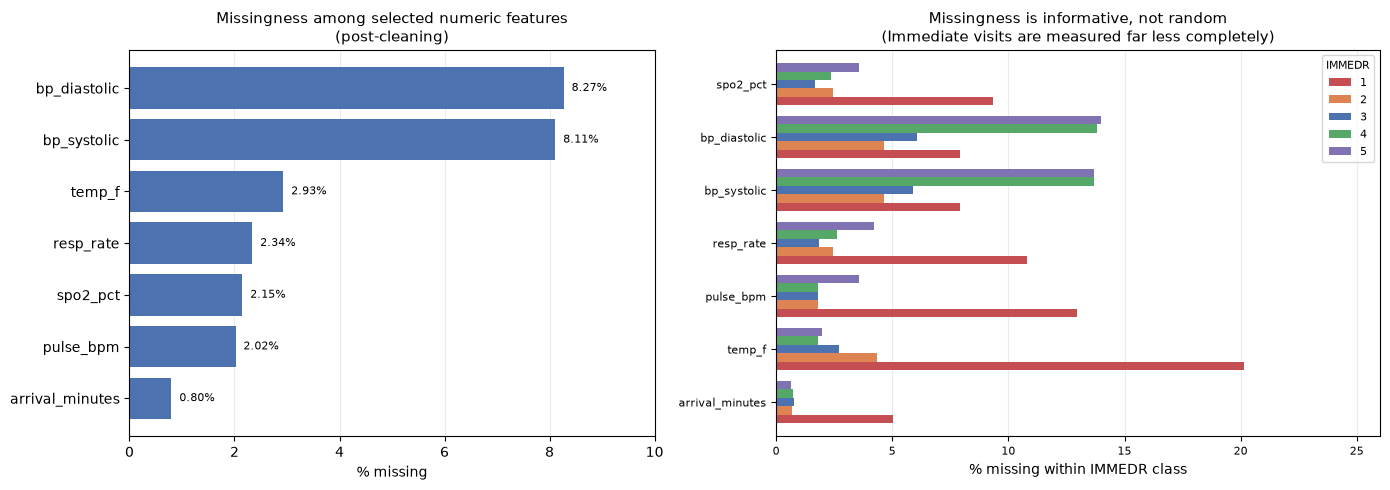

In [16]:
numeric_missing = missingness[missingness["kind"] == "numeric"].copy()

figure, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.15]})

plot_data = numeric_missing.sort_values("pct_missing")
axes[0].barh(plot_data["feature"], plot_data["pct_missing"], color="#4C72B0")
axes[0].set_xlabel("% missing")
axes[0].set_title("Missingness among selected numeric features\n(post-cleaning)", fontsize=11)
axes[0].set_xlim(0, 10)
for i, value in enumerate(plot_data["pct_missing"]):
    axes[0].text(value + 0.15, i, f"{value:.2f}%", va="center", fontsize=8)
axes[0].grid(axis="x", alpha=0.25)
axes[0].set_axisbelow(True)

missing_by_target.T.plot(
    kind="barh", ax=axes[1], width=0.8,
    color=["#C44E52", "#DD8452", "#4C72B0", "#55A868", "#8172B3"],
    legend=True, fontsize=8,
)
axes[1].set_xlabel("% missing within IMMEDR class")
axes[1].set_title(
    "Missingness is informative, not random\n"
    "(Immediate visits are measured far less completely)", fontsize=11,
)
axes[1].legend(title="IMMEDR", fontsize=8, title_fontsize=8)
axes[1].set_xlim(0, 26)
axes[1].grid(axis="x", alpha=0.25)
axes[1].set_axisbelow(True)

figure.tight_layout()
figure.savefig(FIG_DIR / "fig02_missingness.png", dpi=150)
plt.show()

### Range validation — reported, never enforced

Nothing is clipped, winsorised, or deleted by an IQR or z-score rule. After
sentinel resolution **every** observation lies inside its documented range, so such
rules would remove real visits for no analytic gain.

In [17]:
range_report = sn.validate_ranges(X)
range_report[[
    "feature", "documented_lo", "documented_hi", "n_missing",
    "obs_min", "obs_median", "obs_max", "n_below", "n_above",
    "in_documented_range",
]]

,feature,documented_lo,documented_hi,n_missing,obs_min,obs_median,obs_max,n_below,n_above,in_documented_range
0,arrival_minutes,0.0,1439.0,82,0.0,838.0,1439.0,0,0,True
1,temp_f,89.6,105.6,299,91.2,98.1,105.0,0,0,True
2,pulse_bpm,0.0,240.0,206,3.0,89.0,217.0,0,0,True
3,resp_rate,0.0,150.0,239,1.0,18.0,150.0,0,0,True
4,bp_systolic,43.0,289.0,828,43.0,133.0,289.0,0,0,True
5,bp_diastolic,22.0,190.0,844,22.0,79.0,190.0,0,0,True
6,spo2_pct,0.0,100.0,219,0.0,98.0,100.0,0,0,True


In [18]:
print("features with any out-of-range observation:",
      int((~range_report["in_documented_range"]).sum()))
print()
print("Implausible but retained (in-range, yet not physiologically possible):")
flagged = sn.flagged_implausible_counts(X)
flagged

features with any out-of-range observation: 0

Implausible but retained (in-range, yet not physiologically possible):


,feature,value,n,note
0,spo2_pct,0,5,POPCT = 0 % is inside the documented range 0-100 but is ...


## 5. Feature relationships

Two views that bear directly on modelling choices.

`ARREMS` (arrival by ambulance) is a genuine pre-decision signal, and it is also
one of the variables carrying recorded non-response states, which are kept as
their own categories rather than imputed.

`RFV1` is the strongest predictor in the file, and it is also the variable whose
provenance is an assumption — RTI assigned the released code retrospectively from
the verbatim complaint, with a documented 2.4% recoding error rate.

In [19]:
acuity_by_arrival = (
    pd.crosstab(population["ARREMS"], population[target.TARGET_COLUMN], normalize="index")
    .reindex(columns=sorted(target.URGENCY_LABELS), fill_value=0)
    * 100
)
acuity_by_arrival.index = [
    {"1": "Ambulance", "2": "Non-ambulance"}.get(str(i), f"blank ({i})") for i in acuity_by_arrival.index
]
acuity_by_arrival.round(2)

IMMEDR,1,2,3,4,5
blank (-9),2.99,22.39,40.30,31.34,2.99
blank (-8),1.02,26.53,52.04,20.41,0.00
Ambulance,4.39,27.69,54.49,11.60,1.83
Non-ambulance,0.64,12.60,51.91,31.53,3.32


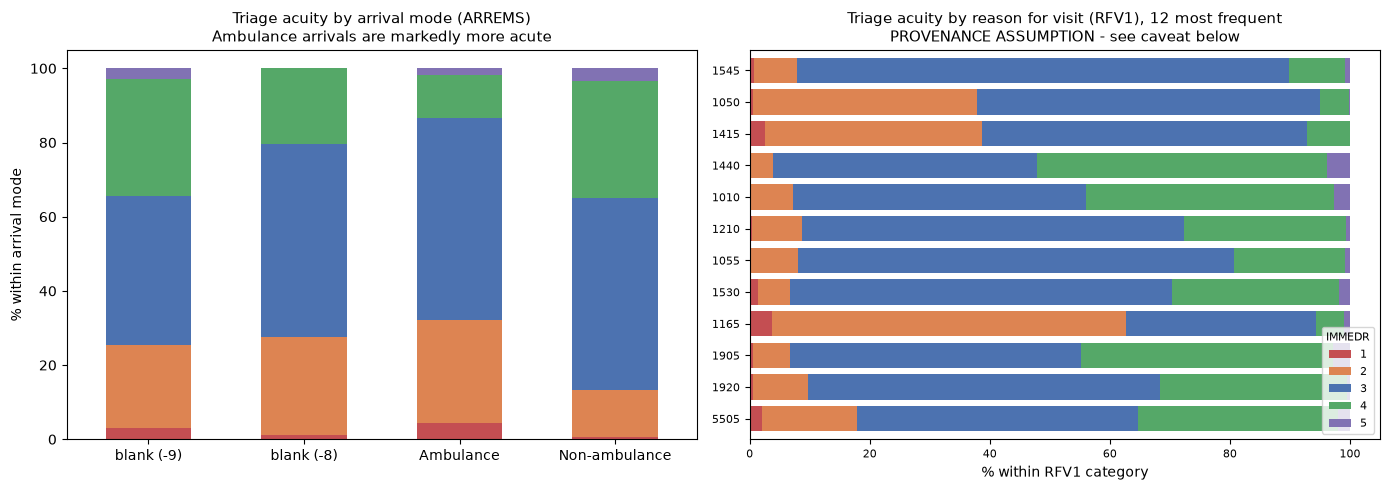

In [20]:
figure, axes = plt.subplots(1, 2, figsize=(14, 5))

acuity_by_arrival.plot(
    kind="bar", stacked=True, ax=axes[0], width=0.55,
    color=["#C44E52", "#DD8452", "#4C72B0", "#55A868", "#8172B3"], legend=False,
)
axes[0].set_ylabel("% within arrival mode")
axes[0].set_xlabel("")
axes[0].set_title(
    "Triage acuity by arrival mode (ARREMS)\n"
    "Ambulance arrivals are markedly more acute", fontsize=11,
)
axes[0].tick_params(axis="x", rotation=0)

slot1 = X["rfv1_broad_category"]
counts = slot1.value_counts()
present = counts[counts > 0].index
top_slots = [c for c in counts.index[:12] if c in set(present)]
shares = (
    pd.crosstab(slot1, population[target.TARGET_COLUMN], normalize="index")
    .reindex(index=top_slots, columns=sorted(target.URGENCY_LABELS), fill_value=0)
    * 100
)
shares.index = [str(i).replace("_", " ") for i in shares.index]
shares.plot(
    kind="barh", stacked=True, ax=axes[1], width=0.8,
    color=["#C44E52", "#DD8452", "#4C72B0", "#55A868", "#8172B3"], legend=True, fontsize=8,
)
axes[1].invert_yaxis()
axes[1].set_xlabel("% within RFV1 category")
axes[1].set_ylabel("")
axes[1].set_title(
    f"Triage acuity by reason for visit (RFV1), {len(top_slots)} most frequent\n"
    "PROVENANCE ASSUMPTION - see caveat below", fontsize=11,
)
axes[1].legend(title="IMMEDR", fontsize=8, title_fontsize=8, loc="lower right")

figure.tight_layout()
figure.savefig(FIG_DIR / "fig03_feature_relationships.png", dpi=150)
plt.show()

**Caveat on the right-hand panel.** `RFV1` reaches Cramer's V 0.41–0.51
against the target, the strongest signal among all 913 variables. The official
documentation also records that RTI assigned this code *retrospectively* from the
verbatim complaint, with a 2.4% recoding error rate. The code is therefore a
central post-hoc abstraction of information that existed before triage. The audit
calls this "the single most consequential judgement in the audit".

These figures are descriptive only. Category selection here is for visualisation
and is **not** used to filter the modelling data.

## 6. Why evaluation must hold out whole hospitals

The dataset spans **147 hospitals**, and they differ systematically in triage
policy and in documentation habit. Two pieces of evidence:

- `HOSPCODE` reaches Cramer's V 0.303 against the target on its own — hospital
  identity is a strong predictor of recorded acuity.
- The share of visits recorded Immediate varies widely between hospitals.

A model validated by randomly splitting rows has already seen each hospital's
idiosyncrasies during training, so it is measured partly on memorisation. This is
the empirical basis for the second half of the research question, and for why
Part 2 will use stratified group k-fold cross-validation on `HOSPCODE`.

`HOSPCODE` is used here **only as a grouping variable for analysis**. It is
excluded from the feature matrix, as §3's leakage guard enforces.

In [21]:
hospital_rates = (
    population.groupby("HOSPCODE")[target.TARGET_COLUMN]
    .value_counts(normalize=True)
    .unstack(fill_value=0.0)
    .reindex(columns=list(target.URGENCY_CLASSES), fill_value=0.0)
)
sizes = population.groupby("HOSPCODE").size()
hospital_rates["n"] = sizes
print("hospitals in modelling population :", len(hospital_rates))
print("visits per hospital               : min %d, median %d, max %d"
      % (sizes.min(), sizes.median(), sizes.max()))
print("singleton hospitals (n = 1)      :", int((sizes == 1).sum()), "(%.2f%%)" % (100 * (sizes == 1).mean()))
print("cramer's V, HOSPCODE vs IMMEDR   : 0.303  (from the audit)")
print()
print("Range of the Immediate share across hospitals:")
print("  min    %.1f%%" % (100 * hospital_rates[1].min()))
print("  median %.1f%%" % (100 * hospital_rates[1].median()))
print("  max    %.1f%%" % (100 * hospital_rates[1].max()))

hospitals in modelling population : 147
visits per hospital               : min 1, median 80, max 164
singleton hospitals (n = 1)      : 6 (4.08%)
cramer's V, HOSPCODE vs IMMEDR   : 0.303  (from the audit)

Range of the Immediate share across hospitals:
  min    0.0%
  median 0.0%
  max    100.0%


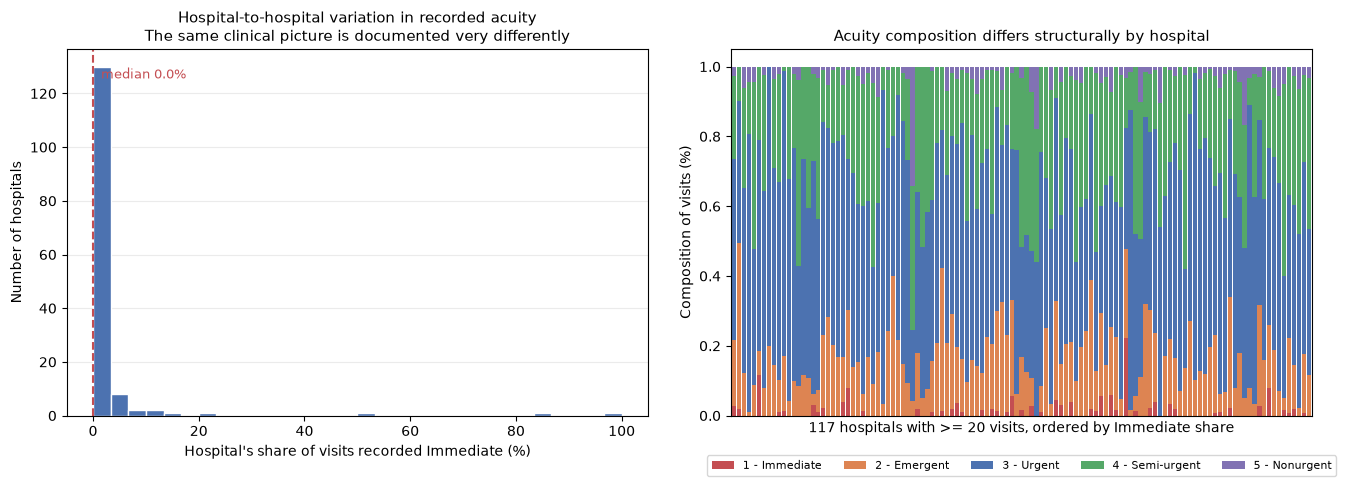

In [22]:
figure, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(100 * hospital_rates[1], bins=30, color="#4C72B0", edgecolor="white")
axes[0].set_xlabel("Hospital's share of visits recorded Immediate (%)")
axes[0].set_ylabel("Number of hospitals")
axes[0].set_title(
    "Hospital-to-hospital variation in recorded acuity\n"
    "The same clinical picture is documented very differently", fontsize=11,
)
axes[0].axvline(100 * hospital_rates[1].median(), color="#C44E52", linestyle="--", linewidth=1.5)
axes[0].text(
    100 * hospital_rates[1].median(), axes[0].get_ylim()[1] * 0.92,
    f"  median {100 * hospital_rates[1].median():.1f}%", color="#C44E52", fontsize=9,
)
axes[0].grid(axis="y", alpha=0.25)
axes[0].set_axisbelow(True)

hospital_rates[sizes >= 20][list(target.URGENCY_CLASSES)].div(
    hospital_rates[sizes >= 20][list(target.URGENCY_CLASSES)].sum(axis=1), axis=0
).plot(
    kind="bar", stacked=True, ax=axes[1], width=0.85, legend=False,
    color=["#C44E52", "#DD8452", "#4C72B0", "#55A868", "#8172B3"],
)
axes[1].set_xticks([])
axes[1].set_xlabel(f"{int((sizes >= 20).sum())} hospitals with >= 20 visits, ordered by Immediate share")
axes[1].set_ylabel("Composition of visits (%)")
axes[1].set_title(
    "Acuity composition differs structurally by hospital", fontsize=11,
)
axes[1].legend(
    [f"{c} - {target.URGENCY_LABELS[c]}" for c in target.URGENCY_CLASSES],
    fontsize=8, ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.18),
)

figure.tight_layout()
figure.savefig(FIG_DIR / "fig04_hospital_variation.png", dpi=150)
plt.show()

## 7. The preprocessing pipeline

A single `Pipeline` around a four-block `ColumnTransformer`, with
`remainder="drop"`.

| Block | Steps |
|---|---|
| Numeric (7) | median imputer + missingness indicator → standard scaler |
| Binary flags (2) | passthrough, unscaled |
| Categorical, low cardinality (6) | constant imputer → one-hot |
| Categorical, RFV (5) | constant imputer → one-hot, `min_frequency=10` |

Every learned parameter — medians, category vocabularies, rare-category
thresholds, scaling moments — is fitted **inside** `Pipeline.fit` on training data
only. Nothing is precomputed on the full dataset.

In [23]:
pipeline = ft.preprocessing_only()
pipeline

,steps,"[('preprocess', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('method_flags', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Proof 1 — nothing is fitted before `fit` is called

If any statistic had been computed on the full dataset during setup, `transform`
would already work.

In [24]:
from sklearn.exceptions import NotFittedError

try:
    pipeline.transform(X.head(10))
    print("FAIL: transform succeeded before fit - something was fitted globally")
except NotFittedError:
    print("PASS: NotFittedError raised. No preprocessing was fitted on the full dataset.")

PASS: NotFittedError raised. No preprocessing was fitted on the full dataset.


### Proof 2 — parameters are learned from training data only

A random split is used purely to *demonstrate the fitting boundary*. It is **not**
the validation strategy: hospitals differ in triage policy, so the real evaluation
in Part 2 will hold out whole hospitals via `HOSPCODE`.

In [25]:
train_index, holdout_index = train_test_split(
    X.index, test_size=0.25, random_state=config.RANDOM_STATE, stratify=y,
)
X_train, X_holdout = X.loc[train_index], X.loc[holdout_index]
y_train, y_holdout = y.loc[train_index], y.loc[holdout_index]

print(f"train   : {len(X_train):,} rows")
print(f"holdout : {len(X_holdout):,} rows")
print("holdout class counts:", dict(y_holdout.value_counts().sort_index()))
print()
print("No metric is computed. This split exists only to show the fitting boundary.")

train   : 7,655 rows
holdout : 2,552 rows
holdout class counts: {1: np.int64(35), 2: np.int64(399), 3: np.int64(1335), 4: np.int64(706), 5: np.int64(77)}

No metric is computed. This split exists only to show the fitting boundary.


In [26]:
pipeline.fit(X_train)                       # <-- the ONLY fit call

Z_train = pipeline.transform(X_train)
Z_holdout = pipeline.transform(X_holdout)

print("transformed train  :", Z_train.shape)
print("transformed holdout:", Z_holdout.shape)
assert Z_train.shape[1] == Z_holdout.shape[1], "column count differs between folds"
print("identical column count for both folds: True")

transformed train  : (7655, 493)
transformed holdout: (2552, 493)
identical column count for both folds: True


In [27]:
transformer = pipeline.named_steps["preprocess"]
numeric_block = transformer.named_transformers_["numeric"]
rfv_encoder = transformer.named_transformers_["categorical_high"].named_steps["onehot"]

print("Imputer medians  :", np.round(numeric_block.named_steps["impute"].statistics_, 2))
print("Scaler means     :", np.round(numeric_block.named_steps["scale"].mean_, 2))
print("RFV categories   :", len(rfv_encoder.categories_[0]), "slot-1 levels learned on train")
print()
print("Rare categories grouped per slot:",
      [len(a) for a in rfv_encoder.infrequent_categories_], "(threshold 10, from train counts)")

Imputer medians  : [836.   98.1  89.   18.  133.   79.   98. ]
Scaler means     : [8.2352e+02 9.8230e+01 9.2170e+01 1.9560e+01 1.3549e+02 7.9680e+01
 9.7400e+01 1.0000e-02 3.0000e-02 2.0000e-02 2.0000e-02 8.0000e-02
 8.0000e-02 2.0000e-02]
RFV categories   : 317 slot-1 levels learned on train

Rare categories grouped per slot: [193, 208, 221, 205, 186] (threshold 10, from train counts)


### Proof 3 — a full-data fit would have given different parameters

If these numbers matched a pipeline fitted on all 10,207 rows, the train-only
boundary would be cosmetic.

In [28]:
full_data_pipeline = ft.preprocessing_only().fit(X)
full_numeric = full_data_pipeline.named_steps["preprocess"].named_transformers_["numeric"]
full_rfv = (
    full_data_pipeline.named_steps["preprocess"]
    .named_transformers_["categorical_high"].named_steps["onehot"]
)

# add_indicator=True appends one indicator per numeric column, so each scaler
# holds 2 x len(NUMERIC) entries. Compare the measurements only.
train_scaler = numeric_block.named_steps["scale"]
full_scaler = full_numeric.named_steps["scale"]
n_measurements = len(ft.NUMERIC)
print("scaler entries per block:",
      len(train_scaler.mean_), f"= {n_measurements} measurements + {n_measurements} missingness indicators")
print()

comparison = pd.DataFrame(
    {
        "train-only fit": train_scaler.mean_[:n_measurements],
        "full-data fit": full_scaler.mean_[:n_measurements],
    },
    index=list(ft.NUMERIC),
)
comparison["differs"] = ~np.isclose(
    comparison["train-only fit"], comparison["full-data fit"]
)
comparison.round(4)

scaler entries per block: 14 = 7 measurements + 7 missingness indicators



,train-only fit,full-data fit,differs
arrival_minutes,823.5180,824.5589,True
temp_f,98.2260,98.2318,True
pulse_bpm,92.1734,92.0049,True
resp_rate,19.5616,19.6081,True
bp_systolic,135.4884,135.2846,True
bp_diastolic,79.6772,79.5825,True
spo2_pct,97.3975,97.3943,True


In [29]:
print("All", len(comparison), "scaler means differ between train-only and full-data fits:",
      bool(comparison["differs"].all()))
print("RFV slot-1 categories: train-only",
      len(rfv_encoder.categories_[0]), "vs full-data", len(full_rfv.categories_[0]))
print()
print("=> the preprocessing statistics are genuinely learned from training folds only.")

All 7 scaler means differ between train-only and full-data fits: True
RFV slot-1 categories: train-only 317 vs full-data 326

=> the preprocessing statistics are genuinely learned from training folds only.


### `handle_unknown="infrequent_if_exist"` is required, not cosmetic

Grouped validation holds out whole hospitals, so every evaluation fold contains
complaint categories absent from training. Plain `"ignore"` encodes such a
category as an all-zero row — which a linear model reads as "nothing was observed",
identical to an unremarkable visit. Mapping unseen codes into the rare-category
bucket is the honest encoding.

In [30]:
output_names = list(transformer.get_feature_names_out())
print(f"output columns: {len(output_names)}")
print("  numeric measurements :", sum(1 for n in output_names if n.startswith("numeric__") and "missingindicator" not in n))
print("  missing indicators   :", sum(1 for n in output_names if "missingindicator" in n))
print("  method flags         :", [n for n in output_names if n.startswith("method_flags")])
print("  low-cardinality      :", sum(1 for n in output_names if n.startswith("categorical_low")))
print("  RFV                  :", sum(1 for n in output_names if n.startswith("categorical_high")))
print("  ...of which infrequent buckets:",
      sum(1 for n in output_names if "infrequent" in n))
print()
dead_train = int((np.abs(Z_train).sum(axis=0) == 0).sum())
print("dead all-zero columns on train:", dead_train)
print("  (expected <=1: the BPDIAS palpation flag, whose single record fell in holdout)")

output columns: 493
  numeric measurements : 7
  missing indicators   : 7
  method flags         : ['method_flags__pulse_measured_by_doppler', 'method_flags__bp_diastolic_palpated_or_doppler']
  low-cardinality      : 38
  RFV                  : 439
  ...of which infrequent buckets: 5

dead all-zero columns on train: 1
  (expected <=1: the BPDIAS palpation flag, whose single record fell in holdout)


In [31]:
# The method flags must remain 0/1 - a flag standardised into a z-score stops
# reading as a flag.
for flag in ft.BINARY_FLAGS:
    column = Z_train[:, output_names.index(f"method_flags__{flag}")]
    unique = set(np.unique(column))
    print(f"{flag:38s} unique values {sorted(unique)}")
    assert unique <= {0.0, 1.0}, f"{flag} was altered by scaling"

pulse_measured_by_doppler              unique values [np.float64(0.0), np.float64(1.0)]
bp_diastolic_palpated_or_doppler       unique values [np.float64(0.0)]


In [32]:
print("NaN in holdout matrix:", int(np.isnan(Z_holdout).sum()))
print("inf in holdout matrix:", int(np.isinf(Z_holdout).sum()))
assert not np.isnan(Z_holdout).any() and not np.isinf(Z_holdout).any()
print("=> the holdout matrix is finite without ever seeing the holdout data.")

NaN in holdout matrix: 0
inf in holdout matrix: 0
=> the holdout matrix is finite without ever seeing the holdout data.


## 8. What Part 1 delivers, and what it does not

**Delivered and verified:**

- Official file loaded read-only and verified by size + SHA-256.
- Five-class `IMMEDR` target; 10,207-visit modelling population with every
  exclusion documented.
- 18 raw variables → 20 engineered columns, selected by collection-timing
  evidence rather than correlation with the target.
- Sentinel codes resolved individually; structural absence kept distinct from
  missing data; nothing clipped or deleted by a distribution rule.
- Four-block `Pipeline`/`ColumnTransformer` whose every learned parameter is fitted
  on training folds only — demonstrated three ways, not merely asserted.
- Leakage guards enforced at pipeline-construction time.

**Not delivered — deliberately, because it is Part 2:** any classifier, any
accuracy or macro-F1 figure, any hospital-grouped cross-validation.

**Outstanding and gating submission:** instructor approval of the dataset is not
recorded in the audit.

**Known limitation carried forward:** the RFV provenance assumption (§5), the
1.36% Immediate class, hospital clustering across 147 hospitals, and 5 retained
`POPCT = 0` values.

## AI Assistance Disclosure

AI assistance was used during the development of this assignment for code review,
debugging, methodological discussion, documentation refinement, and reproducibility
checks.

The project team reviewed, tested, and validated the resulting implementation, and
is responsible for the submitted analysis, code, interpretations, and conclusions.